## Gradient Boosting

This notebook trains and evaluates a Gradient Boosting model to predict combined vehicle fuel consumption in litres per 100 km.

The same cleaned dataset, features and train/test split are used as in the other models.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from data_setup import (
    load_data,
    get_train_test_split,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
)

### Test/Train Split

In [9]:
df = load_data()

X_train, X_test, y_train, y_test = get_train_test_split(df)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Duplicate rows removed: 10867
Training rows: 19288
Testing rows: 4823


### Preprocessing

Categorical features are converted using one-hot encoding, while numerical features are passed through unchanged.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES
        ),
        (
            "numeric", "passthrough", NUMERIC_FEATURES
        )
    ]
)

### Training the model

A sklearn pipeline combines preprocessing with the Gradient Boosting model

the model uses 200 trees, learning rate of 0.1 and a maximum tree depth of 3. (Tuned later on in the notebook)

In [11]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )),
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['year','engine_cylinders','engine_displacement',...,'transmission', 'turbocharger','fuel_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically

### Model Evaluation

The model is evaluated using the same three metrics as the other models:

- MAE
- RMSE
- R²

In [12]:
y_pred = model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f} L/100 km")
print(f"RMSE: {rmse:.3f} L/100 km")
print(f"R²: {r2:.3f}")

MAE: 0.796 L/100 km
RMSE: 1.111 L/100 km
R²: 0.876


### Checking for Overfitting

Boosting focuses on the examples that earlier trees got wrong, so it can fit the training data too closely. To check this, the R² on the training set is compared with the R² on the test set.

If the training score is much higher than the test score, the model is overfitting.

In [13]:
train_r2 = r2_score(y_train, model.predict(X_train))

print(f"Train R²: {train_r2:.3f}")
print(f"Test R²: {r2:.3f}")

Train R²: 0.874
Test R²: 0.876


### Hyperparameter Tuning

The starting settings are compared with other combinations of number of trees, learning rate and tree depth. Grid search with 3-fold cross-validation is used, and the best combination is chosen using MAE on the training data only, so the test set stays unseen.

In [14]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "regressor__n_estimators": [200, 300],
    "regressor__learning_rate": [0.05, 0.1],
    "regressor__max_depth": [3, 5],
}

search = GridSearchCV(
    model,
    param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best settings:", search.best_params_)

Best settings: {'regressor__learning_rate': 0.1, 'regressor__max_depth': 5, 'regressor__n_estimators': 300}


In [15]:
best_pred = search.predict(X_test)

print(f"MAE: {mean_absolute_error(y_test, best_pred):.3f} L/100 km")
print(f"RMSE: {mean_squared_error(y_test, best_pred) ** 0.5:.3f} L/100 km")
print(f"R²: {r2_score(y_test, best_pred):.3f}")

print("Train R²:", r2_score(y_train, search.predict(X_train)))
print("Test R²:", r2_score(y_test, best_pred))

MAE: 0.656 L/100 km
RMSE: 0.911 L/100 km
R²: 0.917
Train R²: 0.9291256996745988
Test R²: 0.9165904432174092


### Inspecting Predictions

The actual and predicted fuel-consumption values are compared directly.

A positive error means that the model underestimated fuel consumption, while a negative error means that it overestimated it.

In [16]:
results = pd.DataFrame({
    "actual": y_test,
    "predicted": best_pred
})

results.to_csv("../results/gradient_boosting_results.csv")

results["error"] = results["actual"] - results["predicted"]

results.head(20)

,actual,predicted,error
14532,13.067500,12.971999,0.095501
199,23.521500,21.670217,1.851283
8086,11.760750,12.840054,-1.079304
17477,10.691591,10.437022,0.254569
20575,11.200714,11.027775,0.172940
23648,12.379737,11.452480,0.927256
22945,13.067500,12.298825,0.768675
5259,11.760750,12.569038,-0.808288
13421,9.046731,9.768538,-0.721807
17731,12.379737,11.831526,0.548211


### Prediction Errors

The plot below shows prediction error against actual fuel consumption.

Values close to zero represent more accurate predictions. Comparing this plot with the Linear Regression one shows whether Gradient Boosting handles high fuel consumption better.

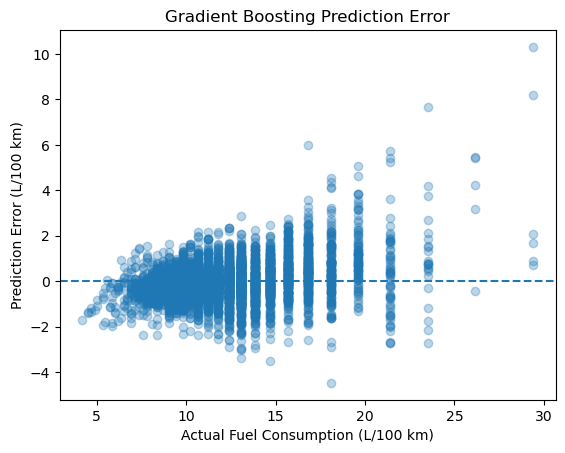

In [17]:
plt.scatter(results["actual"], results["error"], alpha=0.3)
plt.axhline(0, linestyle="--")

plt.xlabel("Actual Fuel Consumption (L/100 km)")
plt.ylabel("Prediction Error (L/100 km)")
plt.title("Gradient Boosting Prediction Error")

plt.show()

### Largest Prediction Errors

The observations with the largest absolute prediction errors are examined to see where the Gradient Boosting model performs poorly.

This is compared with the Linear Regression results to check whether the same vehicles are still the hardest to predict.

In [18]:
results["absolute_error"] = results["error"].abs()

worst_errors = results.sort_values(
    "absolute_error",
    ascending=False
).head(20)

worst_errors

,actual,predicted,error,absolute_error
945,29.401875,19.094572,10.307303,10.307303
7676,29.401875,21.199362,8.202513,8.202513
6072,23.521500,15.859346,7.662154,7.662154
23559,16.801071,10.830205,5.970866,5.970866
5371,21.383182,15.657376,5.725805,5.725805
3302,26.135000,20.692771,5.442229,5.442229
1808,21.383182,15.954545,5.428637,5.428637
1880,26.135000,20.718895,5.416105,5.416105
14205,21.383182,16.160486,5.222696,5.222696
3334,19.601250,14.541909,5.059341,5.059341


### Feature Importance

Gradient Boosting gives an estimate of how much each feature contributed to the predictions. The ten most important features are shown below.

Because OneHotEncoding splits each categorical attribute into separate columns, the importance of an attribute like `fuel type` is spread over several rows.

In [19]:
best_model = search.best_estimator_

feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
importances = best_model.named_steps["regressor"].feature_importances_

importance = pd.Series(importances, index=feature_names)
importance.sort_values(ascending=False).head(10)

numeric__engine_displacement                                  0.687841
numeric__year                                                 0.080806
numeric__engine_cylinders                                     0.062338
categorical__drive_Front-Wheel Drive                          0.031899
categorical__fuel_type_Diesel                                 0.025159
categorical__transmission_Automatic 3-Speed                   0.014997
categorical__drive_4-Wheel or All-Wheel Drive                 0.013448
categorical__class_Midsize Cars                               0.005864
categorical__transmission_Manual 5-Speed                      0.005860
categorical__transmission_Automatic (variable gear ratios)    0.004506
dtype: float64